In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/bank_marketing_cleaned.csv')

In [ ]:
df.head()

,Age,Job Role,Marital Status,Education Level,Credit Default,Account Balance,Housing Loan,Personal Loan,Contact Method,Contact Day,Contact Month,Call Duration (Seconds),Current Campaign Contacts,Days Since Previous Contact,Previous Campaign Contacts,Previous Campaign Outcome,Subscription Status
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 45211
Number of columns: 17


In [ ]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Age                          45211 non-null  int64 
 1   Job Role                     45211 non-null  object
 2   Marital Status               45211 non-null  object
 3   Education Level              45211 non-null  object
 4   Credit Default               45211 non-null  object
 5   Account Balance              45211 non-null  int64 
 6   Housing Loan                 45211 non-null  object
 7   Personal Loan                45211 non-null  object
 8   Contact Method               45211 non-null  object
 9   Contact Day                  45211 non-null  int64 
 10  Contact Month                45211 non-null  object
 11  Call Duration (Seconds)      45211 non-null  int64 
 12  Current Campaign Contacts    45211 non-null  int64 
 13  Days Since Previous Contact  45

In [ ]:
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [ ]:
print(df["Subscription Status"].value_counts())

print("\nSubscription percentages:")
print(
    (df["Subscription Status"].value_counts(normalize=True) * 100)
    .round(2)
)


Subscription Status
no     39922
yes     5289
Name: count, dtype: int64

Subscription percentages:
Subscription Status
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [ ]:

total_contacts = len(df)

successful_subscriptions = (
    df["Subscription Status"].str.lower().eq("yes").sum()
)

conversion_rate = (
    successful_subscriptions / total_contacts
) * 100

print(f"Total contacts: {total_contacts:,}")
print(f"Successful subscriptions: {successful_subscriptions:,}")
print(f"Conversion rate: {conversion_rate:.2f}%")


Total contacts: 45,211
Successful subscriptions: 5,289
Conversion rate: 11.70%


In [ ]:

job_conversion = (
    df.groupby("Job Role")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

print(job_conversion)


Job Role
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: Subscription Status, dtype: float64


In [ ]:

contact_conversion = (
    df.groupby("Contact Method")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

print(contact_conversion)


Contact Method
cellular     14.92
telephone    13.42
unknown       4.07
Name: Subscription Status, dtype: float64


In [ ]:

previous_outcome_conversion = (
    df.groupby("Previous Campaign Outcome")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

print(previous_outcome_conversion)


Previous Campaign Outcome
success    64.73
other      16.68
failure    12.61
unknown     9.16
Name: Subscription Status, dtype: float64


In [ ]:

education_conversion = (
    df.groupby("Education Level")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

print(education_conversion)


Education Level
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: Subscription Status, dtype: float64


In [ ]:

total_records = len(df)

subscribed = df["Subscription Status"].str.lower().eq("yes").sum()
not_subscribed = df["Subscription Status"].str.lower().eq("no").sum()

conversion_rate = subscribed / total_records * 100
non_conversion_rate = not_subscribed / total_records * 100

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Campaign Records",
        "Successful Subscriptions",
        "Unsuccessful Subscriptions",
        "Conversion Rate (%)",
        "Non-Conversion Rate (%)"
    ],
    "Value": [
        total_records,
        subscribed,
        not_subscribed,
        round(conversion_rate, 2),
        round(non_conversion_rate, 2)
    ]
})

kpi_summary


,Metric,Value
0,Total Campaign Records,45211.0
1,Successful Subscriptions,5289.0
2,Unsuccessful Subscriptions,39922.0
3,Conversion Rate (%),11.7
4,Non-Conversion Rate (%),88.3


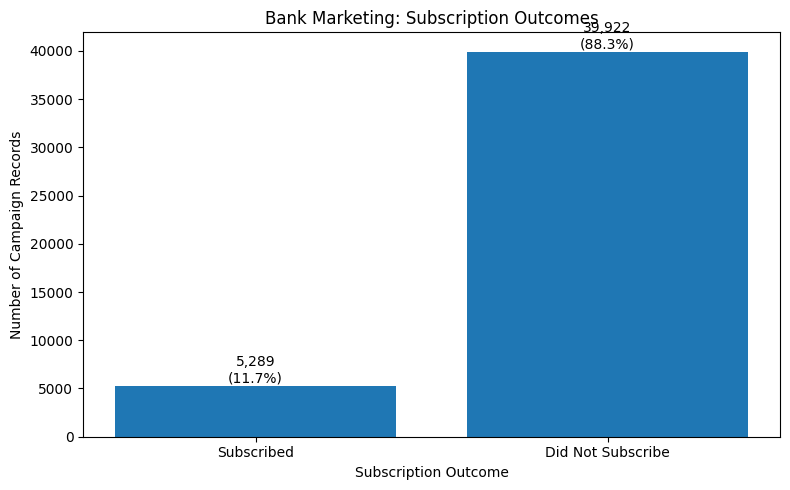

In [ ]:

import matplotlib.pyplot as plt

outcome_counts = df["Subscription Status"].str.lower().value_counts()
outcome_counts = outcome_counts.reindex(["yes", "no"])

plt.figure(figsize=(8, 5))
bars = plt.bar(
    ["Subscribed", "Did Not Subscribe"],
    outcome_counts.values
)

plt.title("Bank Marketing: Subscription Outcomes")
plt.xlabel("Subscription Outcome")
plt.ylabel("Number of Campaign Records")

for bar, value in zip(bars, outcome_counts.values):
    percentage = value / len(df) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


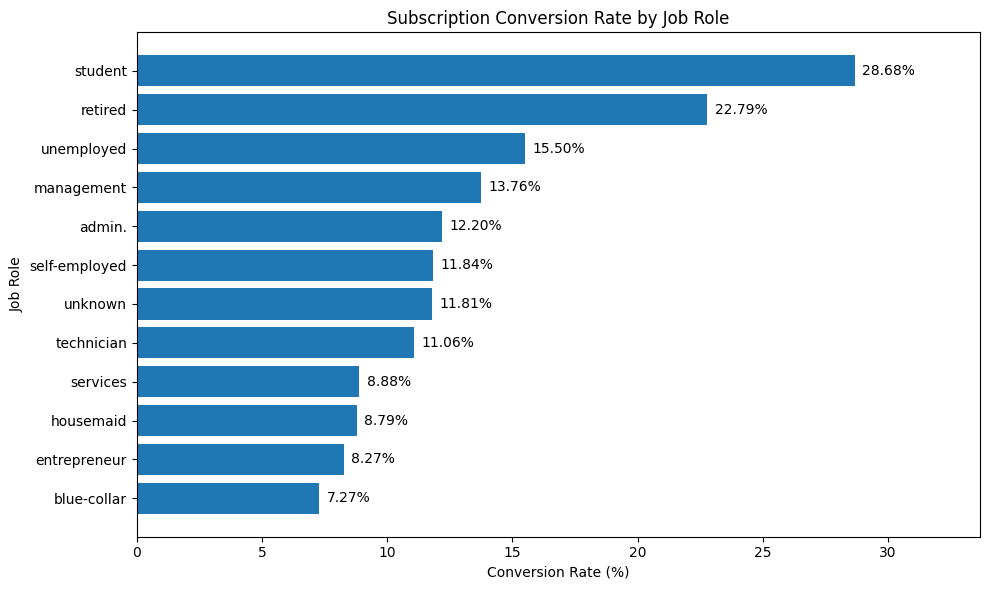

In [ ]:

import matplotlib.pyplot as plt

job_conversion = (
    df.groupby("Job Role")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values()
)

plt.figure(figsize=(10, 6))

bars = plt.barh(job_conversion.index, job_conversion.values)

plt.title("Subscription Conversion Rate by Job Role")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Job Role")

for bar, value in zip(bars, job_conversion.values):
    plt.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center"
    )

plt.xlim(0, job_conversion.max() + 5)
plt.tight_layout()
plt.show()


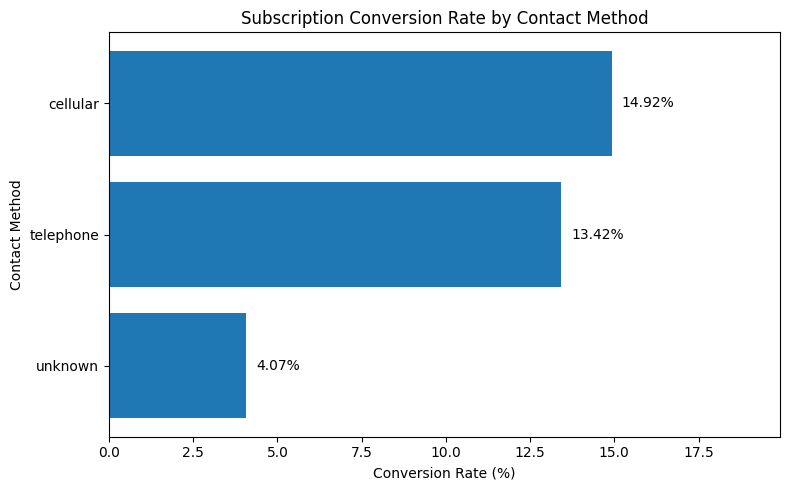

In [ ]:

import matplotlib.pyplot as plt

contact_conversion = (
    df.groupby("Contact Method")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values()
)

plt.figure(figsize=(8, 5))

bars = plt.barh(
    contact_conversion.index,
    contact_conversion.values
)

plt.title("Subscription Conversion Rate by Contact Method")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Contact Method")

for bar, value in zip(bars, contact_conversion.values):
    plt.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center"
    )

plt.xlim(0, contact_conversion.max() + 5)
plt.tight_layout()
plt.show()


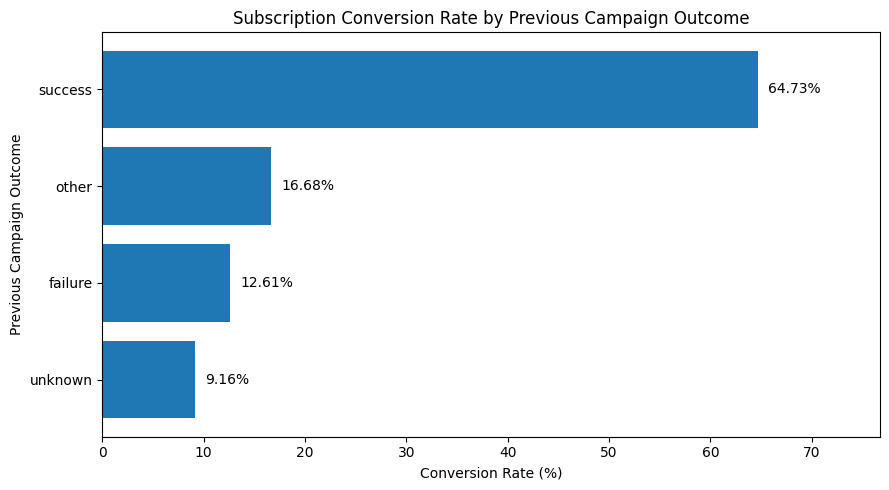

In [ ]:

import matplotlib.pyplot as plt

previous_conversion = (
    df.groupby("Previous Campaign Outcome")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values()
)

plt.figure(figsize=(9, 5))

bars = plt.barh(
    previous_conversion.index,
    previous_conversion.values
)

plt.title("Subscription Conversion Rate by Previous Campaign Outcome")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Previous Campaign Outcome")

for bar, value in zip(bars, previous_conversion.values):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center"
    )

plt.xlim(0, previous_conversion.max() + 12)
plt.tight_layout()
plt.show()


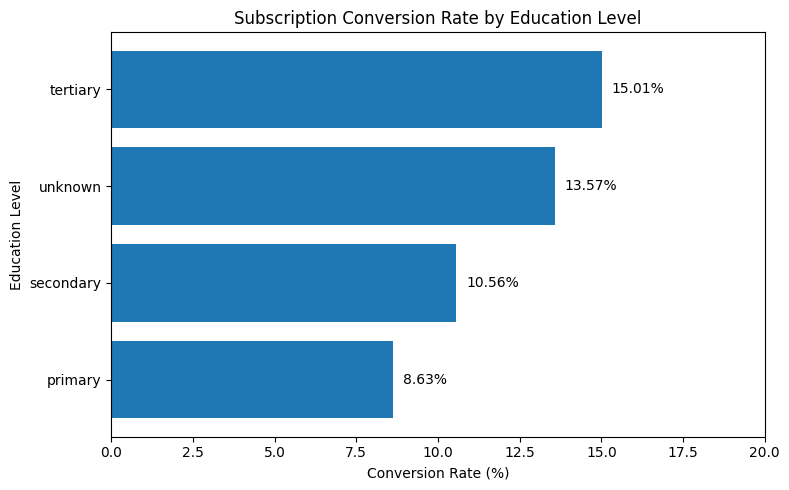

In [ ]:

import matplotlib.pyplot as plt

education_conversion = (
    df.groupby("Education Level")["Subscription Status"]
    .apply(lambda x: x.str.lower().eq("yes").mean() * 100)
    .sort_values()
)

plt.figure(figsize=(8, 5))

bars = plt.barh(
    education_conversion.index,
    education_conversion.values
)

plt.title("Subscription Conversion Rate by Education Level")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Education Level")

for bar, value in zip(bars, education_conversion.values):
    plt.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center"
    )

plt.xlim(0, education_conversion.max() + 5)
plt.tight_layout()
plt.show()


In [ ]:

# Create a reusable conversion summary function
def create_conversion_summary(column):
    summary = (
        df.groupby(column)["Subscription Status"]
        .agg(
            Total_Records="count",
            Subscriptions=lambda x: x.str.lower().eq("yes").sum()
        )
        .reset_index()
    )

    summary["Conversion_Rate_Pct"] = (
        summary["Subscriptions"] / summary["Total_Records"] * 100
    ).round(2)

    return summary.sort_values(
        "Conversion_Rate_Pct", ascending=False
    )


# Generate summaries
job_summary = create_conversion_summary("Job Role")
contact_summary = create_conversion_summary("Contact Method")
education_summary = create_conversion_summary("Education Level")
previous_summary = create_conversion_summary("Previous Campaign Outcome")

# Display one example
job_summary


,Job Role,Total_Records,Subscriptions,Conversion_Rate_Pct
8,student,938,269,28.68
5,retired,2264,516,22.79
10,unemployed,1303,202,15.50
4,management,9458,1301,13.76
0,admin.,5171,631,12.20
6,self-employed,1579,187,11.84
11,unknown,288,34,11.81
9,technician,7597,840,11.06
7,services,4154,369,8.88
3,housemaid,1240,109,8.79


In [ ]:

from google.colab import files
import os

# Create an output folder
os.makedirs("tableau_exports", exist_ok=True)

# Save all four summaries
job_summary.to_csv(
    "tableau_exports/job_conversion_summary.csv", index=False
)
contact_summary.to_csv(
    "tableau_exports/contact_conversion_summary.csv", index=False
)
education_summary.to_csv(
    "tableau_exports/education_conversion_summary.csv", index=False
)
previous_summary.to_csv(
    "tableau_exports/previous_outcome_summary.csv", index=False
)

# Bundle the files into one ZIP
import shutil
shutil.make_archive("tableau_exports", "zip", "tableau_exports")

# Download the ZIP
files.download("tableau_exports.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>